# MOSUM structural-change analysis: WTI crude vs the US Dollar Index (DXY)

**Data.** Daily closes from Yahoo Finance via `yfinance`: WTI front-month futures (`CL=F`) and the ICE US Dollar Index (`DX-Y.NYB`).

**Method.** The MOSUM (moving-sum) multiple change-point procedure of Eichinger & Kirch (2018, *Bernoulli*) and its multiscale extensions (Cho & Kirch, 2022, *Annals of the Institute of Statistical Mathematics*), as implemented in the `mosum` Python package (a port of the R package of the same name).

## How MOSUM works

For a bandwidth $G$ the detector compares the mean of the $G$ observations to the left of each time $k$ with the mean of the $G$ observations to the right, scaled by a local variance estimate:

$$T_G(k)=\sqrt{\frac{G}{2}}\;\frac{\bar X_{(k-G,\,k]}-\bar X_{(k,\,k+G]}}{\hat\sigma_k}, \qquad k=G,\dots,n-G .$$

A change in mean is declared at every $k$ where $|T_G(k)|$ exceeds the asymptotic critical value at level $\alpha$ **and** is the largest exceedance within an $\eta G$ neighbourhood (the *$\eta$-criterion*). The multiscale variants run several bandwidths and merge the candidates, either by **bottom-up merging** (accept the finest-scale candidates first and drop coarser ones that are too close) or by **localised pruning** (rank candidates by $p$-value and keep those that improve a Schwarz information criterion locally). The package also provides bootstrap confidence intervals for the estimated change-point locations.

## Why the scenarios are built the way they are

MOSUM detects **changes in the mean of a series whose noise is stationary**. Raw price levels are integrated (random-walk-like), so applying MOSUM to them flags "breaks" almost everywhere: the mean of a random walk is always drifting. Scenarios G and H show this on purpose. The informative scenarios therefore transform the two prices into (approximately) stationary objects first:

| Scenario | Series | What a change point means |
|---|---|---|
| A | WTI daily log return | shift in the average drift of oil |
| B | DXY daily log return | shift in the average drift of the dollar |
| C | WTI absolute log return | shift in the oil volatility regime |
| D | DXY absolute log return | shift in the dollar volatility regime |
| E, E2 | product of locally standardised WTI and DXY returns | shift in the WTI–DXY **correlation** regime |
| F, F2 | OLS residual of log WTI on log DXY | shift in the long-run **level** relationship |
| G, H | log price levels (reference only) | why MOSUM must not be applied to I(1) data |

Every scenario is run at three single bandwidths and then with the two multiscale procedures. The standard bandwidth set is about one quarter, half a year and one year of trading days. Because the relationship between the two prices moves over years rather than months, the joint scenarios are run a second time (E2, F2) with a multi-year set of one, two and three years. Section 6 pools all change points, looks for breaks that WTI and DXY share, and checks sensitivity to the significance level and to the bandwidth grid.

A change-point *date* throughout is the **first trading day of the new regime**.

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
import yfinance as yf
import mosum
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)

START = "2000-01-01"               # CL=F history on Yahoo begins 2000-08-23; DXY earlier
END = None                         # None -> latest close available
TICKERS = {"WTI": "CL=F", "DXY": "DX-Y.NYB"}

ALPHA = 0.05                       # significance level of the asymptotic critical values
BANDWIDTHS = [63, 126, 252]        # trading days: ~1 quarter, ~half a year, ~1 year
SLOW_BANDWIDTHS = [252, 504, 756]  # trading days: ~1, 2 and 3 years, for slow-moving relationships
ETA = 0.4                          # minimal spacing between change points, relative to G
VOL_WINDOW = 63                    # trailing window for the local-volatility standardisation (Scenario E)
ROLL_CORR = 252                    # window of the descriptive rolling correlation shown with Scenario E
CI_REPS = 500                      # bootstrap replicates for change-point confidence intervals
MATCH_TOL_DAYS = 60                # calendar-day tolerance when matching WTI and DXY break dates
SEED = 20261119

OUT_DIR = Path.cwd() if Path.cwd().name == "ai_folder" else Path.cwd() / "ai_folder"
OUT_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"figure.figsize": (13, 4), "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 200)
np.random.seed(SEED)

print("mosum", getattr(mosum, "__version__", "0.2.0"), "| yfinance", yf.__version__,
      "| pandas", pd.__version__, "| output folder:", OUT_DIR)

mosum 0.2.0 | yfinance 1.2.0 | pandas 1.5.3 | output folder: C:\sourcecode\de-dollarisation-oil\ai_folder


## 2. Download and align the prices

Aligned observations: 6,587 | 2000-08-23 to 2026-11-19


,count,mean,std,min,25%,50%,75%,max
WTI,6587.0,65.369,24.589,-37.63,47.05,64.75,83.215,145.29
DXY,6587.0,92.730,11.067,71.33,82.71,93.49,99.775,120.90


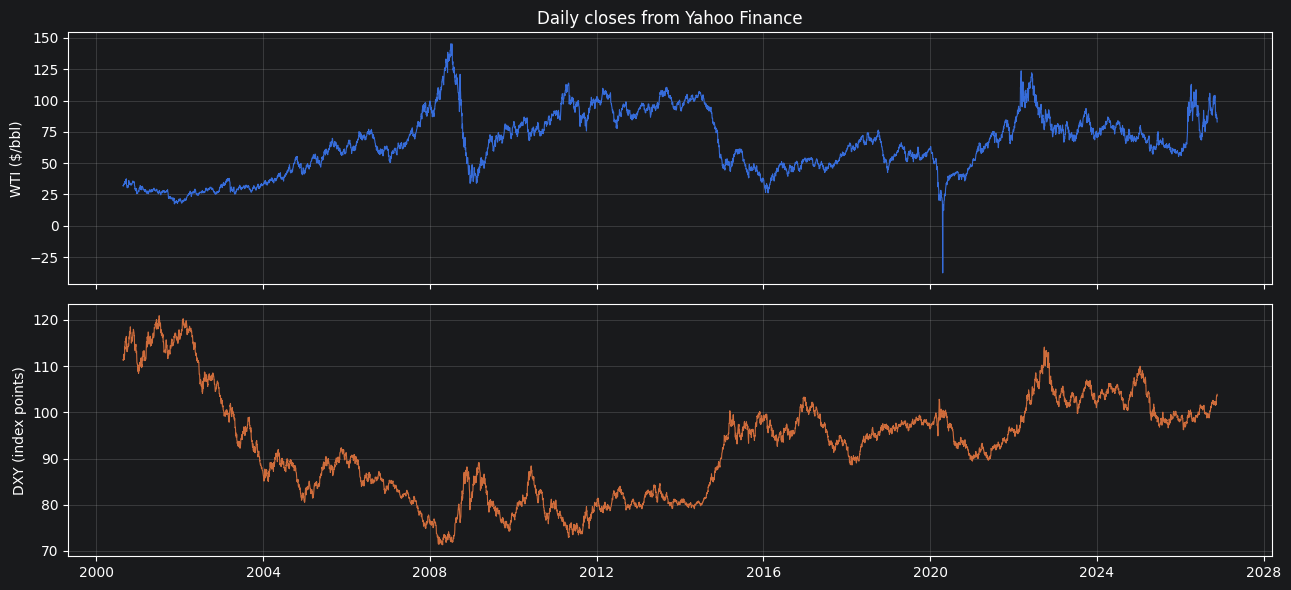

In [2]:
series = {}
for label, ticker in TICKERS.items():
    history = yf.download(ticker, start=START, end=END, auto_adjust=True, progress=False)
    if history.empty:
        raise RuntimeError(f"No observations returned for {ticker}. Check the symbol or the connection.")
    close = history["Close"]
    if isinstance(close, pd.DataFrame):          # recent yfinance returns MultiIndex columns
        close = close.iloc[:, 0]
    series[label] = pd.to_numeric(close, errors="coerce").rename(label)

prices = pd.concat(series.values(), axis=1).replace([np.inf, -np.inf], np.nan).dropna()
prices = prices.loc[~prices.index.duplicated(keep="first")].sort_index()
if prices.index.tz is not None:
    prices.index = prices.index.tz_localize(None)
prices.to_csv(OUT_DIR / "wti_dxy_prices.csv", index_label="Date")

print(f"Aligned observations: {len(prices):,} | {prices.index.min().date()} to {prices.index.max().date()}")
display(prices.describe().T.round(3))

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].plot(prices.index, prices["WTI"], color="C0", lw=0.8)
axes[0].set_ylabel("WTI ($/bbl)")
axes[0].set_title("Daily closes from Yahoo Finance")
axes[1].plot(prices.index, prices["DXY"], color="C1", lw=0.8)
axes[1].set_ylabel("DXY (index points)")
plt.tight_layout()
plt.show()

## 3. Construct the scenario variables

* **Log returns** $r_t = 100\,(\log P_t - \log P_{t-1})$ in percent. WTI printed a negative close (−37.63 $/bbl on 2020-04-20) which has no logarithm, so the two returns touching that day are dropped. The volatility explosion of March–April 2020 is still fully visible in the surrounding days.
* **Absolute returns** $|r_t|$ as the volatility proxy (more robust to the heavy tails than squared returns; MOSUM on $|r_t|$ detects changes in the scale of the returns).
* **Locally standardised returns** $z_t = r_t / \hat s_{t-1}$ with $\hat s_{t-1}$ the trailing 63-day standard deviation, lagged one day. The product $z^{WTI}_t z^{DXY}_t$ has local mean approximately equal to the local correlation, so a mean change in the product is a change in the WTI–DXY correlation regime, separated from changes in either volatility.
* **Long-run residual** from a full-sample OLS of $\log WTI$ on $\log DXY$. A mean shift in the residual is a shift in the level relationship between the two prices. This is only meaningful if the residual is stationary (the two series are cointegrated); the ADF test reported below says how far that holds.

Dates with a non-positive close (log return set to NaN around them): [datetime.date(2020, 4, 20)]
log WTI = 13.232 + (-2.020) log DXY   R² = 0.322, n = 6,586
ADF on the residual: statistic -2.878, p-value 0.0479  (stationary at 5%)
Full-sample correlation of daily log returns: -0.137


,n,start,end,mean,sd,lag-1 autocorr
A: WTI log return (%),6584,2000-08-24,2026-11-19,0.023571,2.630815,-0.014998
B: DXY log return (%),6584,2000-08-24,2026-11-19,-0.001136,0.482841,-0.002567
C: WTI absolute log return (%),6584,2000-08-24,2026-11-19,1.802105,1.916682,0.261087
D: DXY absolute log return (%),6584,2000-08-24,2026-11-19,0.360492,0.32119,0.092111
E: WTI x DXY standardised returns,6521,2000-11-22,2026-11-19,-0.144699,1.481536,0.113532
F: log-level OLS residual,6586,2000-08-23,2026-11-19,0.0,0.34882,0.996835
G: log WTI level (reference only),6586,2000-08-23,2026-11-19,4.098817,0.423752,0.99792
H: log DXY level (reference only),6586,2000-08-23,2026-11-19,4.522589,0.11914,0.999179


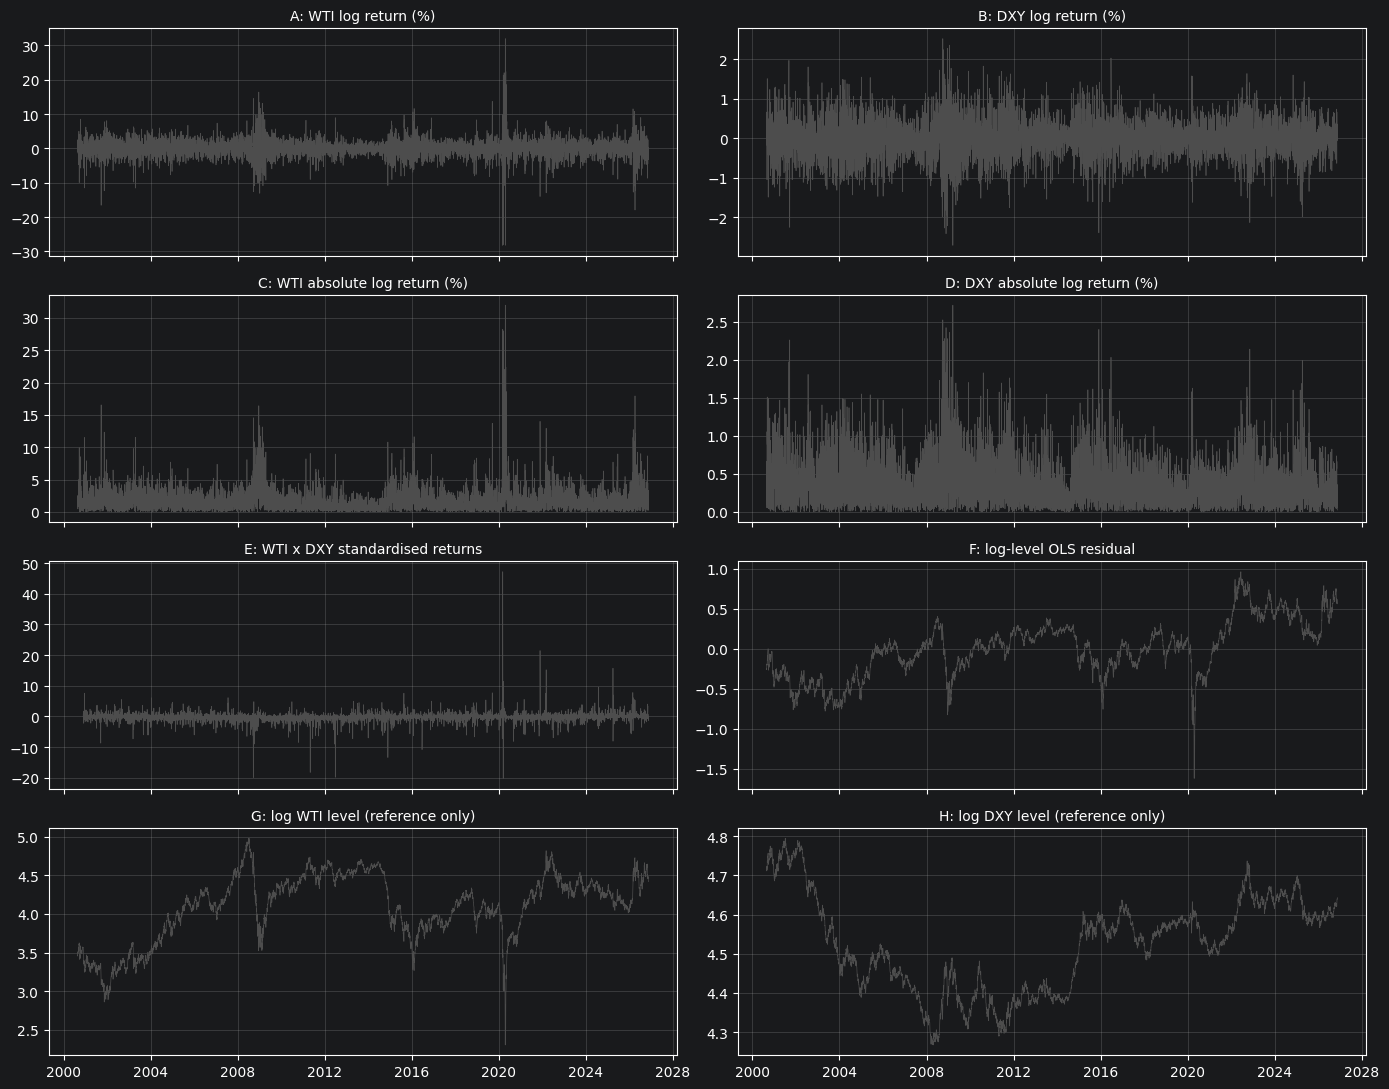

In [3]:
non_positive = prices.index[(prices <= 0).any(axis=1)]
logp = np.log(prices.where(prices > 0))
print("Dates with a non-positive close (log return set to NaN around them):", [d.date() for d in non_positive])

ret = (100 * logp.diff()).dropna()          # drops the first row and the two returns touching the negative print
absret = ret.abs()

local_sd = ret.rolling(VOL_WINDOW, min_periods=VOL_WINDOW).std().shift(1)
z = (ret / local_sd).dropna()
cross = (z["WTI"] * z["DXY"]).rename("WTI_x_DXY")

pair = logp.dropna()
ols = sm.OLS(pair["WTI"], sm.add_constant(pair["DXY"])).fit()
resid = ols.resid.rename("resid")
adf_stat, adf_p, *_ = adfuller(resid, autolag="AIC", regression="c")
print(f"log WTI = {ols.params['const']:.3f} + ({ols.params['DXY']:.3f}) log DXY   R² = {ols.rsquared:.3f}, n = {len(pair):,}")
print(f"ADF on the residual: statistic {adf_stat:.3f}, p-value {adf_p:.4f}  "
      f"({'stationary at 5%' if adf_p < 0.05 else 'unit root NOT rejected at 5% -> Scenario F is indicative only'})")
print(f"Full-sample correlation of daily log returns: {ret['WTI'].corr(ret['DXY']):.3f}")

scenarios = {
    "A: WTI log return (%)":              ret["WTI"],
    "B: DXY log return (%)":              ret["DXY"],
    "C: WTI absolute log return (%)":     absret["WTI"],
    "D: DXY absolute log return (%)":     absret["DXY"],
    "E: WTI x DXY standardised returns":  cross,
    "F: log-level OLS residual":          resid,
    "G: log WTI level (reference only)":  pair["WTI"],
    "H: log DXY level (reference only)":  pair["DXY"],
}

overview = pd.DataFrame({k: {"n": len(v), "start": v.index[0].date(), "end": v.index[-1].date(),
                             "mean": v.mean(), "sd": v.std(), "lag-1 autocorr": v.autocorr(1)}
                         for k, v in scenarios.items()}).T
display(overview)

fig, axes = plt.subplots(4, 2, figsize=(14, 11), sharex=True)
for ax, (name, s) in zip(axes.ravel(), scenarios.items()):
    ax.plot(s.index, s.values, lw=0.5, color="0.3")
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

## 4. MOSUM helpers

* `run_single` runs `mosum.mosum` at one bandwidth with the both-sided local variance estimator (`var_est_method="mosum"`), which is robust to the volatility clustering in the return series.
* `run_multiscale` runs `mosum.multiscale_bottomUp` and `mosum.multiscale_localPrune` over a bandwidth set.
* **Autocorrelation adjustment.** The asymptotic critical values assume serially uncorrelated noise. Absolute returns, the standardised-return product and the level residual are positively autocorrelated, which inflates the detector and produces spurious breaks. For those scenarios the critical value is multiplied by $\sqrt{\text{LRV}/\sigma^2}$, where LRV is a Bartlett-kernel (Newey–West) long-run variance; this is the same as replacing the variance estimate by a long-run variance estimate in $T_G(k)$. The reported $p$-values and the bootstrap intervals are *not* adjusted and should be read as optimistic in those scenarios.
* `cpts_table` maps change-point positions to dates; `segment_table` reports the mean and standard deviation of each regime implied by the headline (localised-pruning) segmentation.

In [4]:
HEADLINE = "multiscale localised pruning"
BOTTOM_UP = "multiscale bottom-up"


def method_names(Gs):
    return [f"single G={G}" for G in Gs] + [BOTTOM_UP, HEADLINE]


def newey_west_ratio(x, lags=None):
    '''Bartlett-kernel long-run variance divided by the plain variance (equals 1 for white noise).'''
    x = np.asarray(x, float)
    x = x - x.mean()
    n = len(x)
    if lags is None:
        lags = int(np.floor(4 * (n / 100) ** (2 / 9)))
    g0 = x @ x / n
    lrv = g0 + sum(2 * (1 - l / (lags + 1)) * (x[l:] @ x[:-l]) / n for l in range(1, lags + 1))
    return max(lrv / g0, 0.05), lags


def run_single(s, G, alpha=ALPHA, ratio=1.0):
    x = s.to_numpy(float)
    if ratio == 1.0:
        return mosum.mosum(x, G=G, alpha=alpha, criterion="eta", eta=ETA)
    thr = mosum.criticalValue(len(x), G, G, alpha) * np.sqrt(ratio)
    return mosum.mosum(x, G=G, threshold="custom", threshold_custom=thr, alpha=alpha, criterion="eta", eta=ETA)


def run_multiscale(s, method, alpha=ALPHA, ratio=1.0, Gs=BANDWIDTHS):
    x = s.to_numpy(float)
    Gs = [int(G) for G in Gs]
    if method == "bottom_up":
        if ratio == 1.0:
            return mosum.multiscale_bottomUp(x, G=Gs, alpha=alpha, eta=ETA)
        f = lambda G, n, a: mosum.criticalValue(n, G, G, a) * np.sqrt(ratio)
        return mosum.multiscale_bottomUp(x, G=Gs, threshold="custom", threshold_function=f, alpha=alpha, eta=ETA)
    if ratio == 1.0:
        return mosum.multiscale_localPrune(x, G=Gs, alpha=alpha, criterion="eta", eta=ETA)
    f = lambda G1, G2, n, a: mosum.criticalValue(n, G1, G2, a) * np.sqrt(ratio)
    return mosum.multiscale_localPrune(x, G=Gs, threshold="custom", threshold_function=f, alpha=alpha,
                                       criterion="eta", eta=ETA)


def cpts_table(res, s, scenario, method):
    cols = ["scenario", "method", "position", "date", "G_left", "G_right", "p_value", "jump"]
    info = res.cpts_info
    if info is None or len(info) == 0:
        return pd.DataFrame(columns=cols)
    pos = info["cpts"].to_numpy(int)
    out = pd.DataFrame({"scenario": scenario, "method": method, "position": pos, "date": s.index[pos],
                        "G_left": info["G_left"].to_numpy(int), "G_right": info["G_right"].to_numpy(int),
                        "p_value": info["p_value"].to_numpy(float), "jump": info["jump"].to_numpy(float)})
    return out.sort_values("position").reset_index(drop=True)[cols]


def segment_table(s, cpts):
    bounds = [0, *sorted(int(c) for c in cpts), len(s)]
    rows = []
    for a, b in zip(bounds[:-1], bounds[1:]):
        seg = s.iloc[a:b]
        rows.append({"start": seg.index[0].date(), "end": seg.index[-1].date(), "n": len(seg),
                     "mean": seg.mean(), "sd": seg.std()})
    out = pd.DataFrame(rows)
    out["mean_change"] = out["mean"].diff()
    return out


def plot_scenario(s, singles, headline, title, ylabel):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
    ax1.plot(s.index, s.values, color="0.65", lw=0.5)
    bounds = [0, *sorted(int(c) for c in headline.cpts), len(s)]
    for a, b in zip(bounds[:-1], bounds[1:]):
        seg = s.iloc[a:b]
        ax1.hlines(seg.mean(), seg.index[0], seg.index[-1], color="C3", lw=2.2)
    for c in headline.cpts:
        ax1.axvline(s.index[int(c)], color="C3", ls="--", lw=1)
    ax1.set_title(f"{title}: headline segmentation ({HEADLINE}, {len(headline.cpts)} change points)")
    ax1.set_ylabel(ylabel)
    for i, (G, m) in enumerate(singles.items()):
        ax2.plot(s.index, m.stat, lw=0.7, color=f"C{i}",
                 label=f"G={G}: {len(m.cpts)} cpts, max {np.nanmax(m.stat):.2f} vs threshold {m.threshold_value:.2f}")
        ax2.axhline(m.threshold_value, color=f"C{i}", ls=":", lw=1)
        for c in m.cpts:
            ax2.plot(s.index[int(c)], m.stat[int(c)], marker="v", color=f"C{i}", ms=7)
    ax2.set_ylabel("|MOSUM statistic|")
    ax2.set_ylim(0, np.nanmax([np.nanmax(m.stat) for m in singles.values()]) * 1.25)
    ax2.legend(loc="upper center", fontsize=8, ncol=3)
    ax2.xaxis.set_major_locator(mdates.YearLocator(2))
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    plt.tight_layout()
    plt.show()


def analyse(name, s, ylabel, lrv=False, lrv_lags=None, alpha=ALPHA, Gs=BANDWIDTHS, show=True):
    s = s.dropna()
    ratio, lags = (1.0, 0)
    if lrv:
        ratio, lags = newey_west_ratio(s, lrv_lags)
    singles = {G: run_single(s, G, alpha, ratio) for G in Gs}
    bottom_up = run_multiscale(s, "bottom_up", alpha, ratio, Gs)
    local_prune = run_multiscale(s, "local_prune", alpha, ratio, Gs)
    frames = [cpts_table(m, s, name, f"single G={G}") for G, m in singles.items()]
    frames += [cpts_table(bottom_up, s, name, BOTTOM_UP), cpts_table(local_prune, s, name, HEADLINE)]
    table = pd.concat(frames, ignore_index=True)
    table["lrv_ratio"] = ratio
    table["bandwidths"] = str(list(Gs))
    if show:
        print(f"{name}: n = {len(s):,}, {s.index[0].date()} to {s.index[-1].date()}, "
              f"alpha = {alpha}, bandwidths = {list(Gs)}")
        if lrv:
            print(f"Newey-West long-run variance ratio = {ratio:.2f} (lags = {lags}); "
                  f"critical values inflated by sqrt(ratio) = {np.sqrt(ratio):.2f}")
        counts = pd.DataFrame(index=method_names(Gs), columns=["n_cpts", "dates"])
        for method in counts.index:
            d = table.loc[table["method"] == method, "date"]
            counts.loc[method] = [len(d), ", ".join(pd.Timestamp(x).strftime("%Y-%m-%d") for x in d)]
        display(counts)
        if 0 < len(local_prune.cpts) <= 30:
            print(f"Regimes implied by the headline segmentation ({HEADLINE}):")
            display(segment_table(s, local_prune.cpts).round(4))
        elif len(local_prune.cpts) > 30:
            print(f"{len(local_prune.cpts)} headline change points: segment table omitted.")
        plot_scenario(s, singles, local_prune, name, ylabel)
    return {"name": name, "series": s, "singles": singles, "bottom_up": bottom_up,
            "local_prune": local_prune, "table": table, "ratio": ratio, "Gs": list(Gs)}


results = {}

## 5. Scenarios

### Scenario A: WTI daily log returns (changes in average drift)
Daily returns are close to white noise, so MOSUM's assumptions hold well here. Mean shifts in daily returns are hard to detect because the signal-to-noise ratio is tiny: a sustained bull or bear phase has to persist for roughly a bandwidth to register.

A: WTI log return (%): n = 6,584, 2000-08-24 to 2026-11-19, alpha = 0.05, bandwidths = [63, 126, 252]


,n_cpts,dates
single G=63,0,
single G=126,0,
single G=252,0,
multiscale bottom-up,0,
multiscale localised pruning,0,


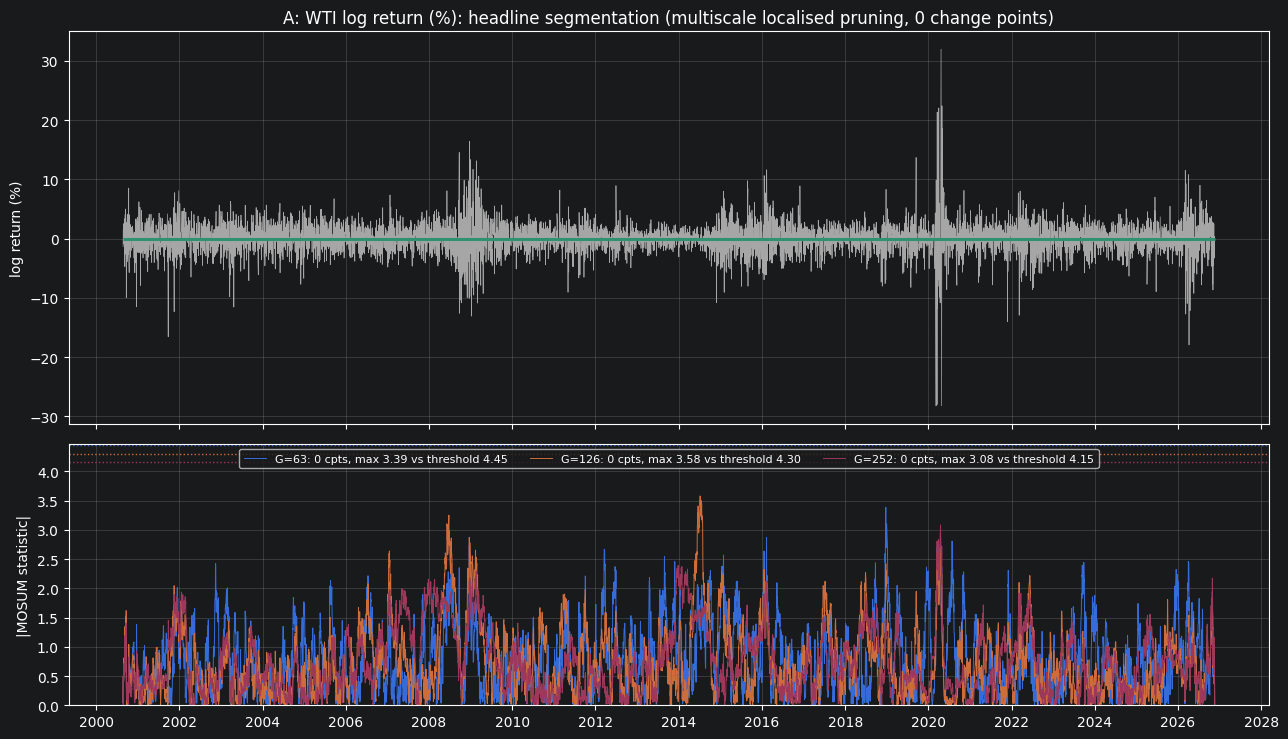

In [5]:
results["A"] = analyse("A: WTI log return (%)", scenarios["A: WTI log return (%)"], "log return (%)")

### Scenario B: DXY daily log returns (changes in average drift)

B: DXY log return (%): n = 6,584, 2000-08-24 to 2026-11-19, alpha = 0.05, bandwidths = [63, 126, 252]


,n_cpts,dates
single G=63,0,
single G=126,0,
single G=252,0,
multiscale bottom-up,0,
multiscale localised pruning,0,


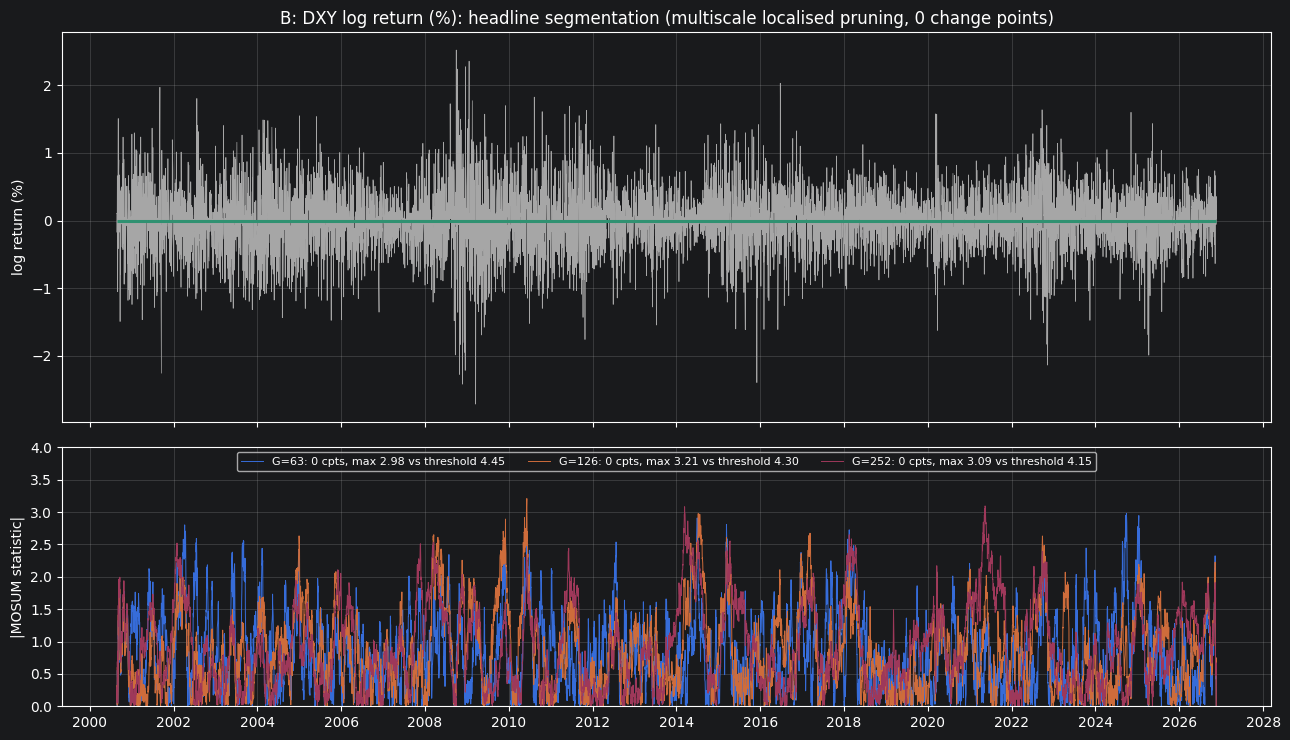

In [6]:
results["B"] = analyse("B: DXY log return (%)", scenarios["B: DXY log return (%)"], "log return (%)")

### Scenario C: WTI absolute returns (volatility regimes)
Absolute returns are strongly positively autocorrelated (volatility clustering), so the autocorrelation adjustment is switched on.

C: WTI absolute log return (%): n = 6,584, 2000-08-24 to 2026-11-19, alpha = 0.05, bandwidths = [63, 126, 252]
Newey-West long-run variance ratio = 3.44 (lags = 10); critical values inflated by sqrt(ratio) = 1.85


,n_cpts,dates
single G=63,0,
single G=126,3,"2008-09-12, 2009-04-13, 2014-10-21"
single G=252,5,"2008-05-20, 2009-08-19, 2014-11-12, 2016-12-02..."
multiscale bottom-up,5,"2008-09-12, 2009-04-13, 2014-10-21, 2016-12-02..."
multiscale localised pruning,8,"2008-09-12, 2009-04-13, 2009-09-24, 2014-11-12..."


Regimes implied by the headline segmentation (multiscale localised pruning):


,start,end,n,mean,sd,mean_change
0,2000-08-24,2008-09-11,2011,1.7385,1.4672,NaN
1,2008-09-12,2009-04-09,145,4.6646,3.4756,2.9261
2,2009-04-13,2009-09-23,115,2.0126,1.6345,-2.6520
3,2009-09-24,2014-11-11,1293,1.2283,1.1045,-0.7844
4,2014-11-12,2014-11-24,9,1.3570,1.1467,0.1287
5,2014-11-25,2016-12-01,507,2.3595,1.8986,1.0025
6,2016-12-02,2020-02-25,811,1.3745,1.3114,-0.9850
7,2020-02-26,2026-02-25,1507,1.9874,2.4921,0.6128
8,2026-02-26,2026-11-19,186,2.9819,2.7610,0.9946


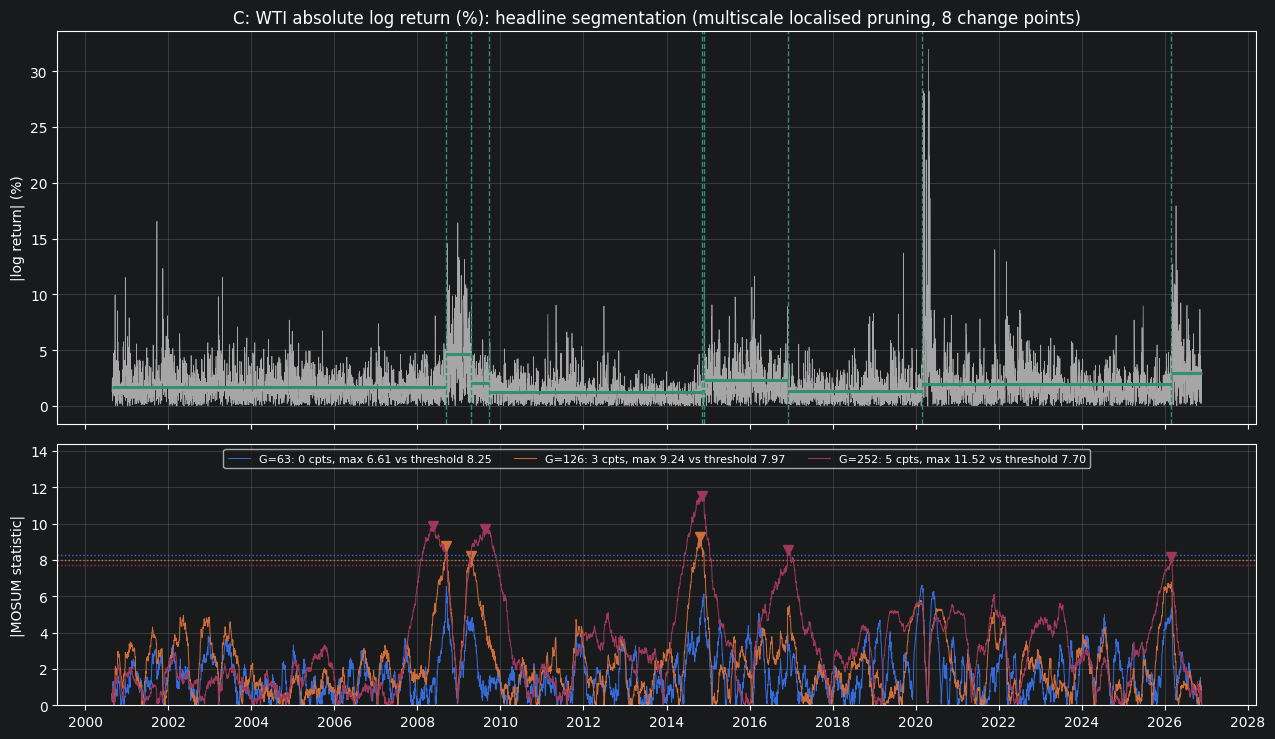

In [7]:
results["C"] = analyse("C: WTI absolute log return (%)", scenarios["C: WTI absolute log return (%)"], "|log return| (%)", lrv=True)

### Scenario D: DXY absolute returns (volatility regimes)

D: DXY absolute log return (%): n = 6,584, 2000-08-24 to 2026-11-19, alpha = 0.05, bandwidths = [63, 126, 252]
Newey-West long-run variance ratio = 2.10 (lags = 10); critical values inflated by sqrt(ratio) = 1.45


,n_cpts,dates
single G=63,0,
single G=126,2,"2014-09-16, 2020-02-20"
single G=252,8,"2006-07-28, 2008-03-11, 2009-09-02, 2012-04-16..."
multiscale bottom-up,8,"2006-07-28, 2008-03-11, 2009-09-02, 2012-04-16..."
multiscale localised pruning,9,"2006-07-28, 2007-09-17, 2008-08-28, 2009-09-02..."


Regimes implied by the headline segmentation (multiscale localised pruning):


,start,end,n,mean,sd,mean_change
0,2000-08-24,2006-07-27,1476,0.4084,0.3307,NaN
1,2006-07-28,2007-09-14,285,0.2394,0.2016,-0.1690
2,2007-09-17,2008-08-27,240,0.3823,0.3081,0.1429
3,2008-08-28,2009-09-01,255,0.6602,0.5533,0.2779
4,2009-09-02,2012-04-13,659,0.4287,0.3420,-0.2315
5,2012-04-16,2013-08-30,347,0.3085,0.2636,-0.1202
6,2013-09-03,2014-08-27,249,0.1968,0.1862,-0.1117
7,2014-08-28,2022-02-18,1880,0.3188,0.2762,0.1220
8,2022-02-22,2023-04-17,289,0.4621,0.3788,0.1432
9,2023-04-18,2026-11-19,904,0.2998,0.2593,-0.1623


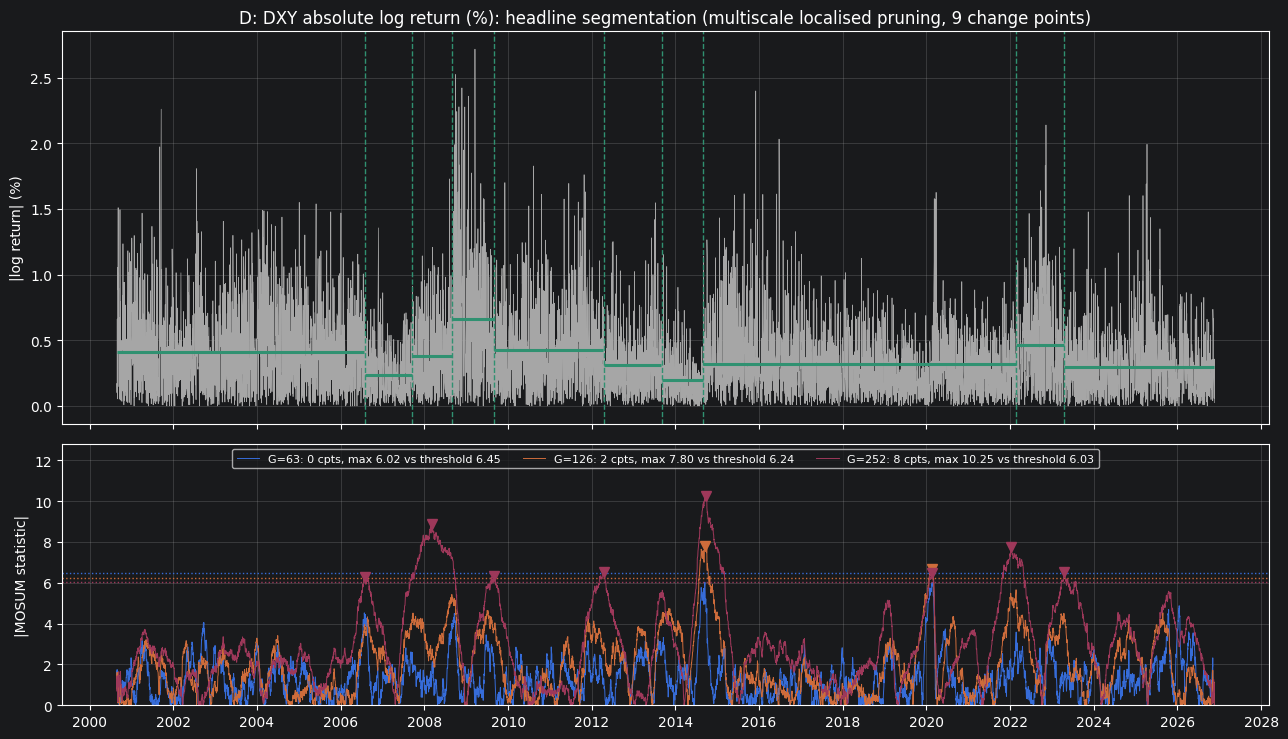

In [8]:
results["D"] = analyse("D: DXY absolute log return (%)", scenarios["D: DXY absolute log return (%)"], "|log return| (%)", lrv=True)

### Scenario E: product of locally standardised returns (correlation regimes)
This is the scenario that speaks most directly to *structural change between* the two prices. The local mean of the product is approximately the local correlation between WTI and DXY returns, so each regime's `mean` in the segment table is an estimate of that regime's correlation. The detector panel reports the maximum of each statistic against its threshold, which shows how far the procedure is from detecting a change at that bandwidth.

E: WTI x DXY standardised returns: n = 6,521, 2000-11-22 to 2026-11-19, alpha = 0.05, bandwidths = [63, 126, 252]
Newey-West long-run variance ratio = 1.46 (lags = 10); critical values inflated by sqrt(ratio) = 1.21


,n_cpts,dates
single G=63,0,
single G=126,0,
single G=252,0,
multiscale bottom-up,0,
multiscale localised pruning,0,


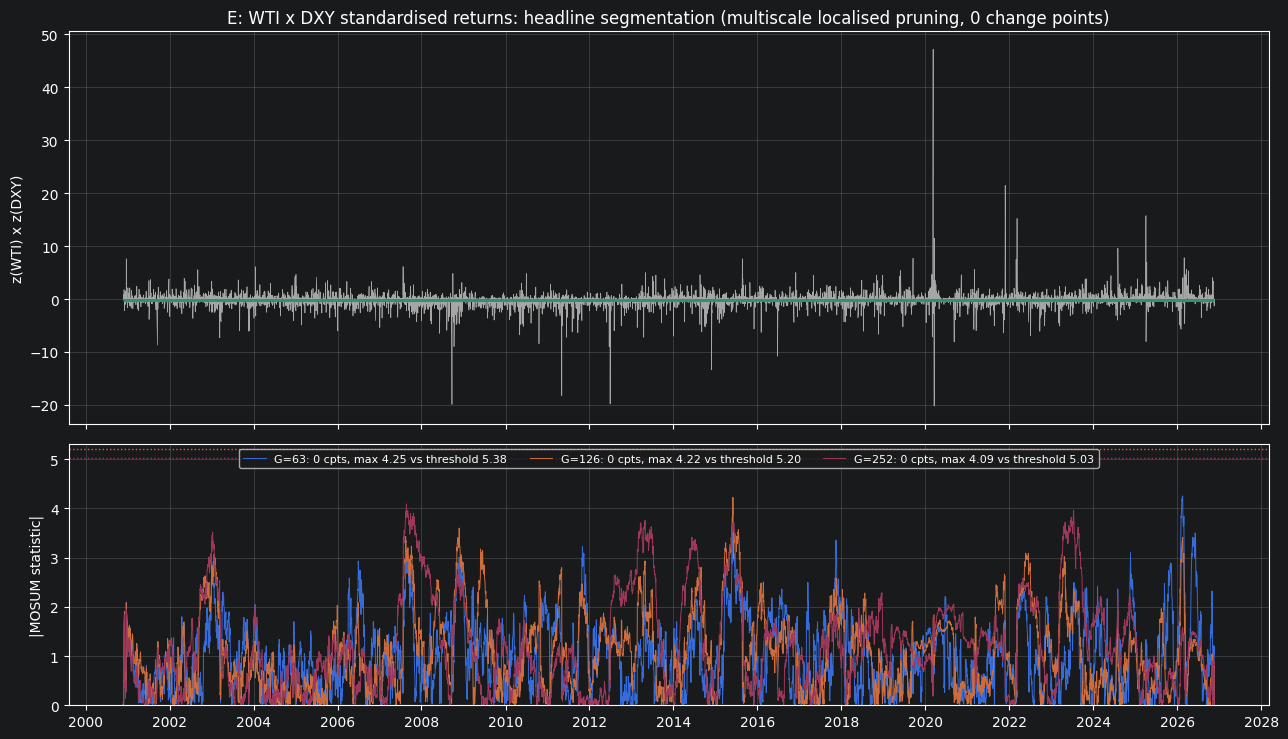

In [9]:
results["E"] = analyse("E: WTI x DXY standardised returns", scenarios["E: WTI x DXY standardised returns"], "z(WTI) x z(DXY)", lrv=True)

### Scenario E2: the same series at multi-year bandwidths
A correlation regime that lasts several years changes the mean of the product by a few tenths against a noise standard deviation above one. The quarterly-to-annual bandwidths average over too few observations to resolve that; one-, two- and three-year windows can.

E2: WTI x DXY standardised returns, multi-year bandwidths: n = 6,521, 2000-11-22 to 2026-11-19, alpha = 0.05, bandwidths = [252, 504, 756]
Newey-West long-run variance ratio = 1.46 (lags = 10); critical values inflated by sqrt(ratio) = 1.21


,n_cpts,dates
single G=252,0,
single G=504,0,
single G=756,1,2007-09-04
multiscale bottom-up,1,2007-09-04
multiscale localised pruning,1,2023-07-14


Regimes implied by the headline segmentation (multiscale localised pruning):


,start,end,n,mean,sd,mean_change
0,2000-11-22,2023-07-13,5677,-0.1881,1.5012,NaN
1,2023-07-14,2026-11-19,844,0.1474,1.3059,0.3355


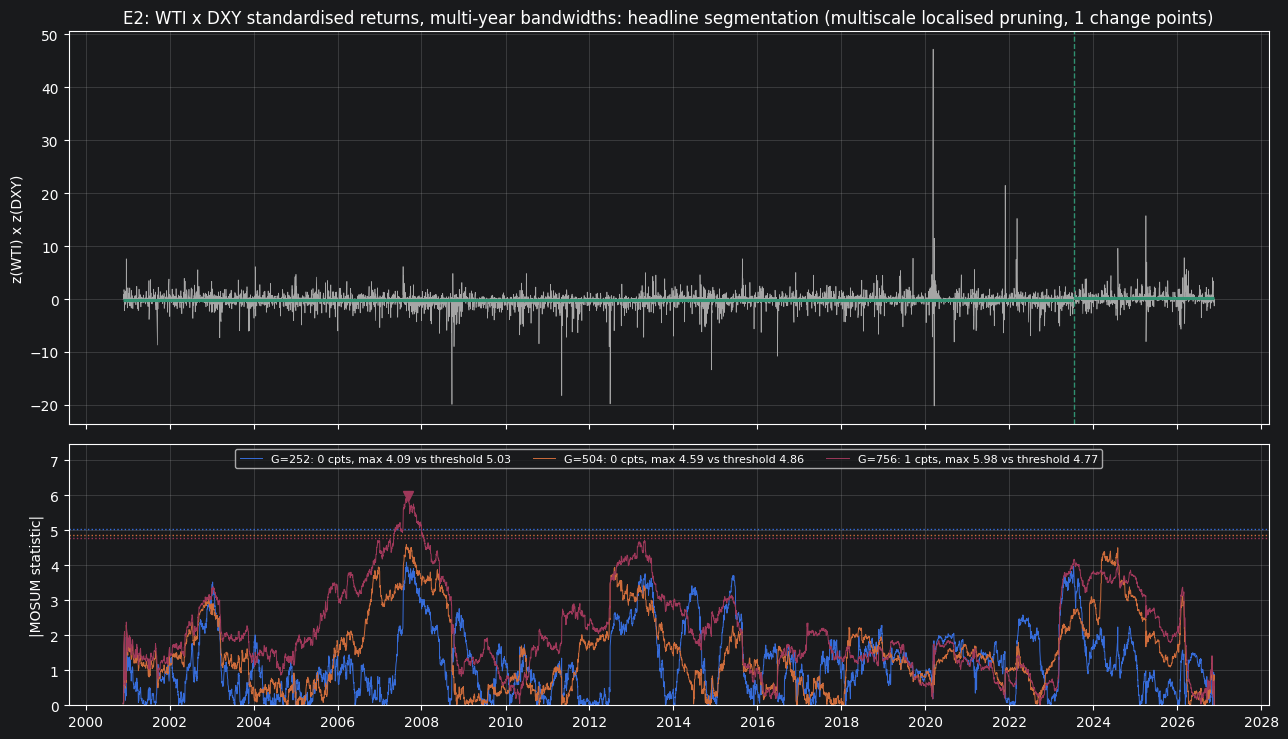

In [10]:
results["E2"] = analyse("E2: WTI x DXY standardised returns, multi-year bandwidths", scenarios["E: WTI x DXY standardised returns"], "z(WTI) x z(DXY)", lrv=True, Gs=SLOW_BANDWIDTHS)

#### Correlation regimes against the rolling correlation
The red steps are the headline regime means of the product (regime correlations) from E2; the blue steps are from E. The grey line is the ordinary 252-day rolling correlation of daily log returns, shown only as a descriptive comparison.

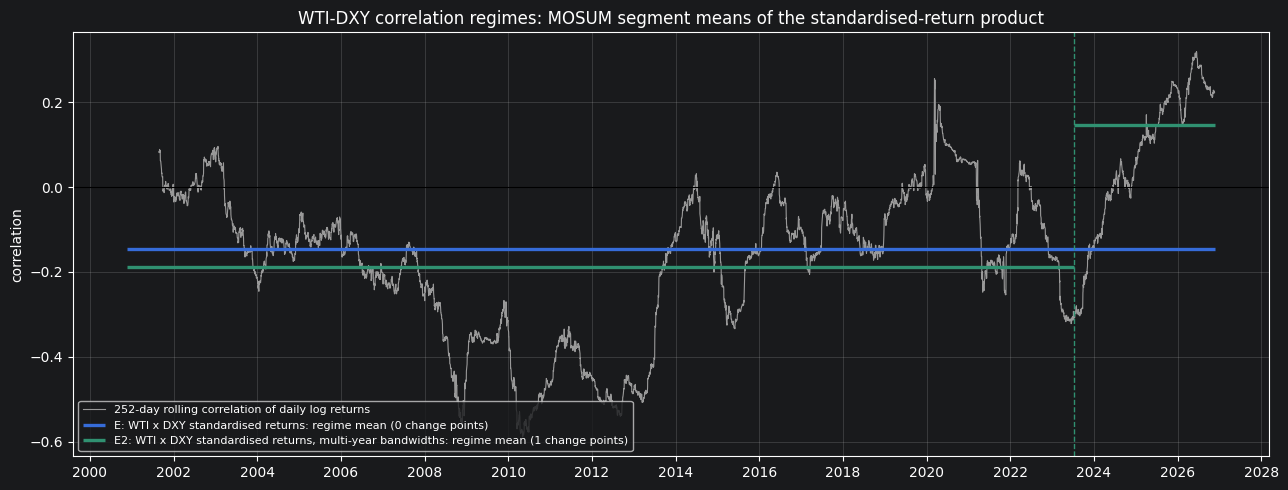

Regime correlations from E2 (headline segmentation):


,start,end,n,mean,sd,mean_change
0,2000-11-22,2023-07-13,5677,-0.188,1.501,NaN
1,2023-07-14,2026-11-19,844,0.147,1.306,0.336


In [11]:
rolling_corr = ret["WTI"].rolling(ROLL_CORR).corr(ret["DXY"])

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(rolling_corr.index, rolling_corr, color="0.6", lw=0.8,
        label=f"{ROLL_CORR}-day rolling correlation of daily log returns")
for key, color in [("E", "C0"), ("E2", "C3")]:
    r = results[key]
    s, lp = r["series"], r["local_prune"]
    bounds = [0, *sorted(int(c) for c in lp.cpts), len(s)]
    for i, (a, b) in enumerate(zip(bounds[:-1], bounds[1:])):
        seg = s.iloc[a:b]
        ax.hlines(seg.mean(), seg.index[0], seg.index[-1], color=color, lw=2.4,
                  label=f"{r['name']}: regime mean ({len(lp.cpts)} change points)" if i == 0 else None)
    for c in lp.cpts:
        ax.axvline(s.index[int(c)], color=color, ls="--", lw=1)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("correlation")
ax.set_title("WTI-DXY correlation regimes: MOSUM segment means of the standardised-return product")
ax.legend(loc="lower left", fontsize=8)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

print("Regime correlations from E2 (headline segmentation):")
display(segment_table(results["E2"]["series"], results["E2"]["local_prune"].cpts).round(3))

### Scenario F: long-run level relationship (OLS residual of log WTI on log DXY)
A mean shift here is a shift in the WTI level that the DXY level "explains". The residual is extremely persistent (lag-1 autocorrelation near 1), so the Newey–West adjustment uses a one-year lag window (252 trading days). The resulting long-run variance ratio is in the hundreds, which is the procedure's way of saying that the residual contains only a handful of effectively independent observations. Whatever is detected here describes *where the spread between the two prices moved*, not a statistically secure regime change.

F: log-level OLS residual: n = 6,586, 2000-08-23 to 2026-11-19, alpha = 0.05, bandwidths = [63, 126, 252]
Newey-West long-run variance ratio = 202.53 (lags = 252); critical values inflated by sqrt(ratio) = 14.23


,n_cpts,dates
single G=63,0,
single G=126,0,
single G=252,0,
multiscale bottom-up,0,
multiscale localised pruning,0,


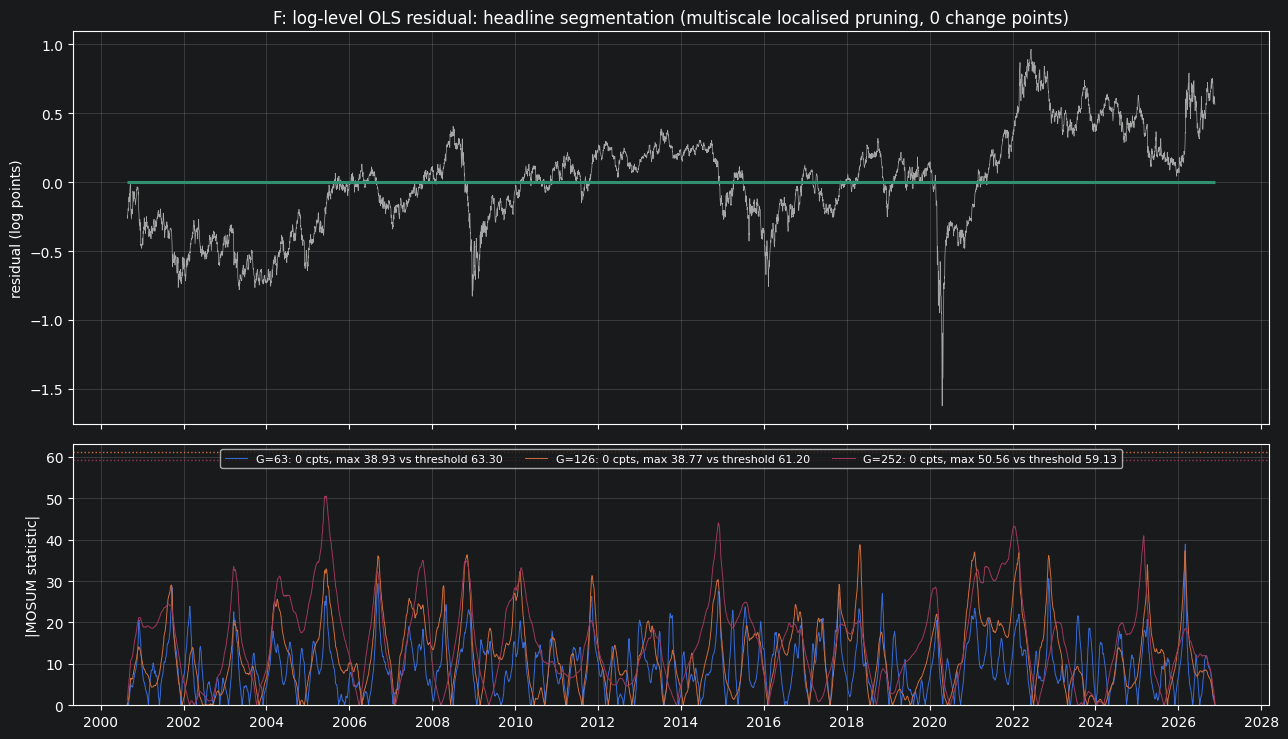

In [12]:
results["F"] = analyse("F: log-level OLS residual", scenarios["F: log-level OLS residual"], "residual (log points)", lrv=True, lrv_lags=252)

### Scenario F2: the same residual at multi-year bandwidths
With a persistence time of roughly a year, only bandwidths of several years average over enough independent information for the detector to move.

F2: log-level OLS residual, multi-year bandwidths: n = 6,586, 2000-08-23 to 2026-11-19, alpha = 0.05, bandwidths = [252, 504, 756]
Newey-West long-run variance ratio = 202.53 (lags = 252); critical values inflated by sqrt(ratio) = 14.23


,n_cpts,dates
single G=252,0,
single G=504,0,
single G=756,2,"2005-05-27, 2014-11-26"
multiscale bottom-up,2,"2005-05-27, 2014-11-26"
multiscale localised pruning,3,"2005-03-23, 2005-06-10, 2014-11-26"


Regimes implied by the headline segmentation (multiscale localised pruning):


,start,end,n,mean,sd,mean_change
0,2000-08-23,2005-03-22,1139,-0.4606,0.1600,NaN
1,2005-03-23,2005-06-09,55,-0.3015,0.0551,0.1591
2,2005-06-10,2014-11-25,2381,0.0398,0.1904,0.3412
3,2014-11-26,2026-11-19,3011,0.1483,0.3502,0.1085


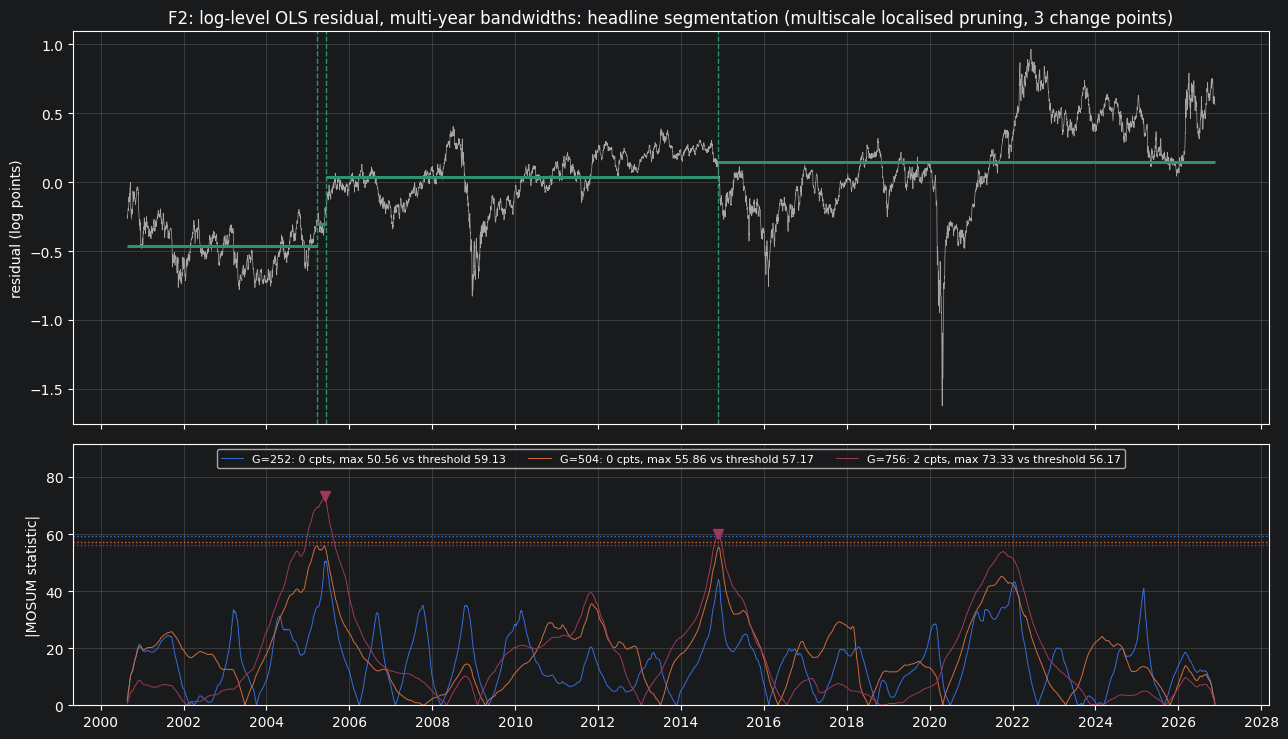

In [13]:
results["F2"] = analyse("F2: log-level OLS residual, multi-year bandwidths", scenarios["F: log-level OLS residual"], "residual (log points)", lrv=True, lrv_lags=252, Gs=SLOW_BANDWIDTHS)

### Scenarios G and H: raw log levels (reference only, assumptions violated)
Included to show what happens when MOSUM is applied directly to the prices. The detector is far above its critical value almost everywhere, so it segments the random-walk path into many "regimes". These results are excluded from the pooled analysis.

G: log WTI level (reference only): n = 6,586, 2000-08-23 to 2026-11-19, alpha = 0.05, bandwidths = [63, 126, 252]


,n_cpts,dates
single G=63,79,"2000-12-04, 2001-02-13, 2001-09-21, 2002-03-04..."
single G=126,40,"2000-12-04, 2001-09-21, 2002-03-27, 2002-08-09..."
single G=252,20,"2001-08-23, 2002-08-14, 2004-07-13, 2005-06-16..."
multiscale bottom-up,79,"2000-12-04, 2001-02-13, 2001-09-21, 2002-03-04..."
multiscale localised pruning,25,"2001-09-21, 2002-03-04, 2004-03-16, 2004-08-04..."


Regimes implied by the headline segmentation (multiscale localised pruning):


,start,end,n,mean,sd,mean_change
0,2000-08-23,2001-09-20,267,3.3771,0.0937,NaN
1,2001-09-21,2002-03-01,109,3.0214,0.0738,-0.3557
2,2002-03-04,2004-03-15,508,3.3902,0.1092,0.3688
3,2004-03-16,2004-08-03,97,3.6560,0.0573,0.2658
4,2004-08-04,2005-06-15,217,3.8918,0.0858,0.2359
5,2005-06-16,2007-09-07,559,4.1653,0.0890,0.2734
6,2007-09-10,2008-03-03,121,4.5040,0.0700,0.3388
7,2008-03-04,2008-10-02,149,4.7708,0.1093,0.2667
8,2008-10-03,2008-11-13,30,4.2529,0.1404,-0.5179
9,2008-11-14,2009-04-29,113,3.8010,0.1294,-0.4518


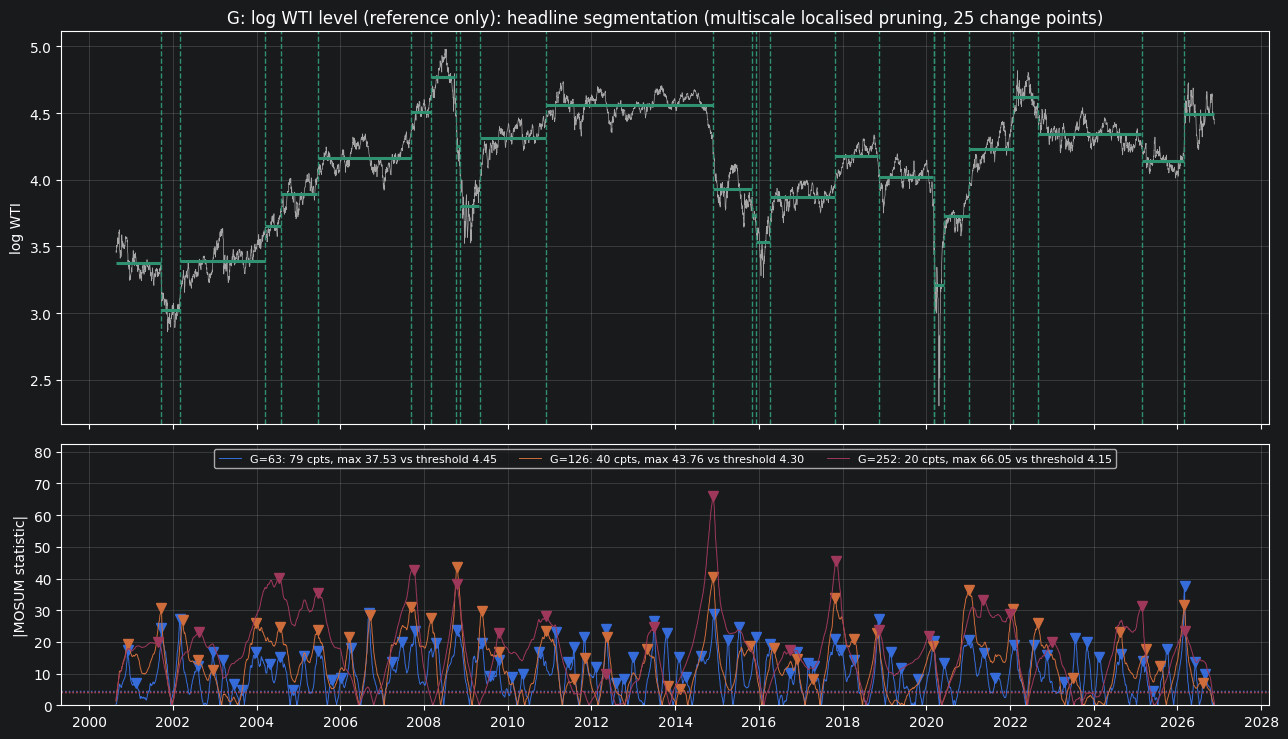

In [14]:
results["G"] = analyse("G: log WTI level (reference only)", scenarios["G: log WTI level (reference only)"], "log WTI")

H: log DXY level (reference only): n = 6,586, 2000-08-23 to 2026-11-19, alpha = 0.05, bandwidths = [63, 126, 252]


,n_cpts,dates
single G=63,75,"2000-12-11, 2001-03-15, 2001-08-08, 2001-11-12..."
single G=126,41,"2001-03-12, 2001-10-19, 2002-05-28, 2003-01-09..."
single G=252,19,"2002-05-20, 2002-12-11, 2005-05-27, 2006-05-09..."
multiscale bottom-up,75,"2000-12-11, 2001-03-15, 2001-08-08, 2001-11-12..."
multiscale localised pruning,3,"2002-12-11, 2007-09-06, 2014-11-04"


Regimes implied by the headline segmentation (multiscale localised pruning):


,start,end,n,mean,sd,mean_change
0,2000-08-23,2002-12-10,571,4.7308,0.0377,NaN
1,2002-12-11,2007-09-05,1184,4.4806,0.0585,-0.2502
2,2007-09-06,2014-11-03,1804,4.3765,0.0446,-0.1041
3,2014-11-04,2026-11-19,3027,4.5868,0.0488,0.2103


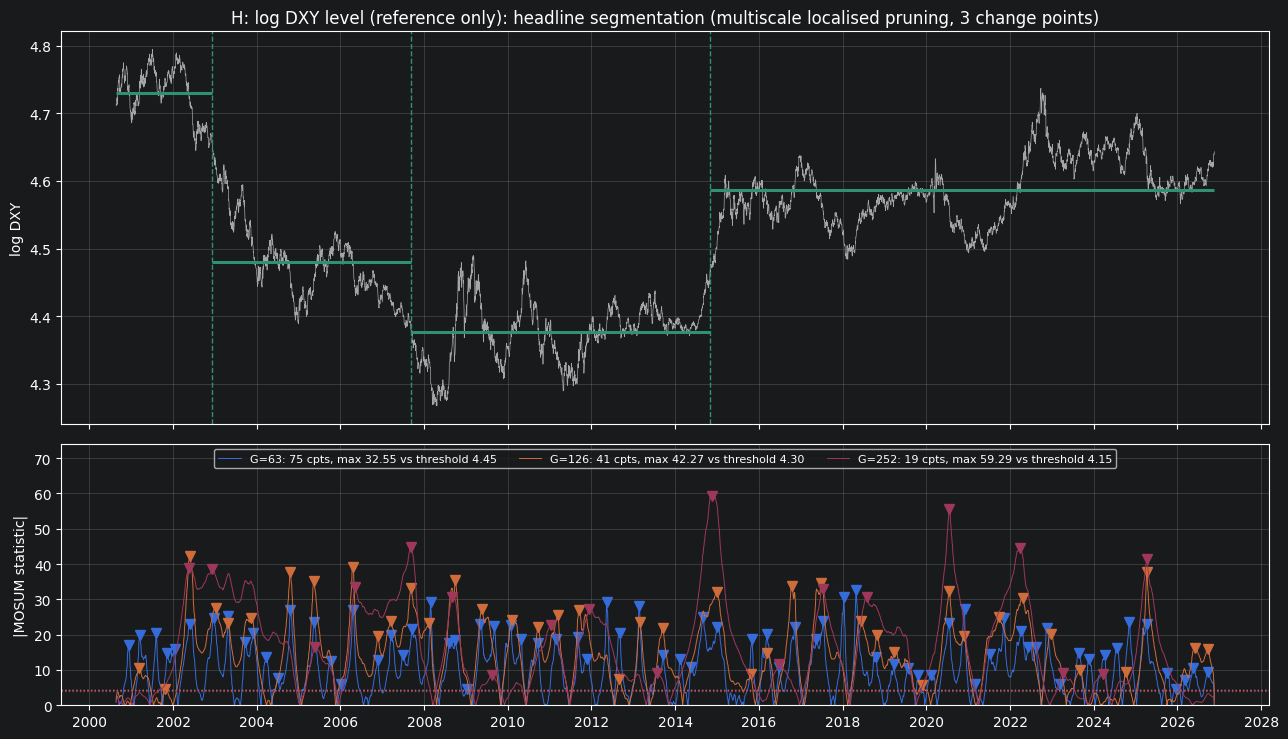

In [15]:
results["H"] = analyse("H: log DXY level (reference only)", scenarios["H: log DXY level (reference only)"], "log DXY")

### Bootstrap confidence intervals for the headline change points
Pointwise 95% bootstrap intervals for the location of each localised-pruning change point in the valid scenarios. The bootstrap resamples residuals independently, so in the autocorrelation-adjusted scenarios (C–F2) the intervals are too narrow.

In [16]:
VALID_KEYS = [k for k in results if k not in ("G", "H")]

np.random.seed(SEED)
ci_rows = []
for key in VALID_KEYS:
    r = results[key]
    lp, s = r["local_prune"], r["series"]
    if len(lp.cpts) == 0:
        continue
    ci = lp.confint(level=0.05, N_reps=CI_REPS)["CI"]
    for c, lo, hi in zip(ci["cpts"], ci["pw.left"], ci["pw.right"]):
        lo_i, hi_i = int(np.clip(lo, 0, len(s) - 1)), int(np.clip(hi, 0, len(s) - 1))
        ci_rows.append({"scenario": r["name"], "cpt_date": s.index[int(c)].date(),
                        "ci95_low": s.index[lo_i].date(), "ci95_high": s.index[hi_i].date(),
                        "width_trading_days": hi_i - lo_i})
ci_table = pd.DataFrame(ci_rows, columns=["scenario", "cpt_date", "ci95_low", "ci95_high", "width_trading_days"])
ci_table.to_csv(OUT_DIR / "mosum_headline_confidence_intervals.csv", index=False)
display(ci_table)

,scenario,cpt_date,ci95_low,ci95_high,width_trading_days
0,C: WTI absolute log return (%),2008-09-12,2008-08-27,2008-09-29,22
1,C: WTI absolute log return (%),2009-04-13,2009-03-17,2009-05-07,36
2,C: WTI absolute log return (%),2009-09-24,2009-08-18,2009-10-30,52
3,C: WTI absolute log return (%),2014-11-12,2014-10-29,2014-11-26,20
4,C: WTI absolute log return (%),2014-11-25,2014-09-23,2015-02-02,90
5,C: WTI absolute log return (%),2016-12-02,2016-09-20,2017-02-15,100
6,C: WTI absolute log return (%),2020-02-26,2019-11-25,2020-05-28,124
7,C: WTI absolute log return (%),2026-02-26,2025-10-13,2026-07-13,186
8,D: DXY absolute log return (%),2006-07-28,2006-06-01,2006-09-22,78
9,D: DXY absolute log return (%),2007-09-17,2007-03-20,2008-05-05,284


## 6. Pooled results

### 6.1 All change points, all scenarios, all methods
Saved to `mosum_change_points.csv`. The `valid_assumptions` flag is `False` for the reference scenarios G and H.

In [17]:
all_cpts = pd.concat([r["table"] for r in results.values()], ignore_index=True)
all_cpts["date"] = pd.to_datetime(all_cpts["date"])
all_cpts["valid_assumptions"] = ~all_cpts["scenario"].str.startswith(("G", "H"))
all_cpts.to_csv(OUT_DIR / "mosum_change_points.csv", index=False)

all_methods = method_names(sorted(set(BANDWIDTHS) | set(SLOW_BANDWIDTHS)))
counts = (all_cpts.groupby(["scenario", "method"]).size().unstack("method")
          .reindex(columns=all_methods).reindex([r["name"] for r in results.values()]))
for r in results.values():                      # blank out bandwidths a scenario did not run
    for m in all_methods:
        if m.startswith("single") and m not in method_names(r["Gs"]):
            counts.loc[r["name"], m] = np.nan
print("Number of change points by scenario and method (blank = bandwidth not run for that scenario):")
display(counts.fillna(0).astype(int).astype(str).where(counts.notna(), ""))

headline_cpts = (all_cpts[(all_cpts["method"] == HEADLINE) & all_cpts["valid_assumptions"]]
                 .sort_values(["scenario", "date"]).reset_index(drop=True))
print(f"Headline ({HEADLINE}) change points in the valid scenarios:")
display(headline_cpts.drop(columns=["valid_assumptions"]).round(4))

Number of change points by scenario and method (blank = bandwidth not run for that scenario):


method,single G=63,single G=126,single G=252,single G=504,single G=756,multiscale bottom-up,multiscale localised pruning
scenario,,,,,,,
A: WTI log return (%),,,,,,,
B: DXY log return (%),,,,,,,
C: WTI absolute log return (%),,3,5,,,5,8
D: DXY absolute log return (%),,2,8,,,8,9
E: WTI x DXY standardised returns,,,,,,,
"E2: WTI x DXY standardised returns, multi-year bandwidths",,,,,1,1,1
F: log-level OLS residual,,,,,,,
"F2: log-level OLS residual, multi-year bandwidths",,,,,2,2,3
G: log WTI level (reference only),79,40,20,,,79,25


Headline (multiscale localised pruning) change points in the valid scenarios:


,scenario,method,position,date,G_left,G_right,p_value,jump,lrv_ratio,bandwidths
0,C: WTI absolute log return (%),multiscale localised pruning,2011,2008-09-12,126,126,0.0000,1.1076,3.4364,"[63, 126, 252]"
1,C: WTI absolute log return (%),multiscale localised pruning,2156,2009-04-13,126,126,0.0000,1.0320,3.4364,"[63, 126, 252]"
2,C: WTI absolute log return (%),multiscale localised pruning,2271,2009-09-24,252,126,0.0000,0.8703,3.4364,"[63, 126, 252]"
3,C: WTI absolute log return (%),multiscale localised pruning,3564,2014-11-12,252,252,0.0000,1.0260,3.4364,"[63, 126, 252]"
4,C: WTI absolute log return (%),multiscale localised pruning,3573,2014-11-25,126,63,0.0000,1.2596,3.4364,"[63, 126, 252]"
5,C: WTI absolute log return (%),multiscale localised pruning,4080,2016-12-02,252,252,0.0000,0.7626,3.4364,"[63, 126, 252]"
6,C: WTI absolute log return (%),multiscale localised pruning,4891,2020-02-26,252,63,0.0000,1.1314,3.4364,"[63, 126, 252]"
7,C: WTI absolute log return (%),multiscale localised pruning,6398,2026-02-26,252,252,0.0000,0.7276,3.4364,"[63, 126, 252]"
8,D: DXY absolute log return (%),multiscale localised pruning,1476,2006-07-28,252,252,0.0002,0.5606,2.1041,"[63, 126, 252]"
9,D: DXY absolute log return (%),multiscale localised pruning,1761,2007-09-17,126,252,0.0002,0.6856,2.1041,"[63, 126, 252]"


### 6.2 Timeline of detected change points (valid scenarios)
Large stars are the headline (localised-pruning) change points; diamonds are bottom-up merging; small dots are single-bandwidth results. Dotted vertical lines mark reference events.

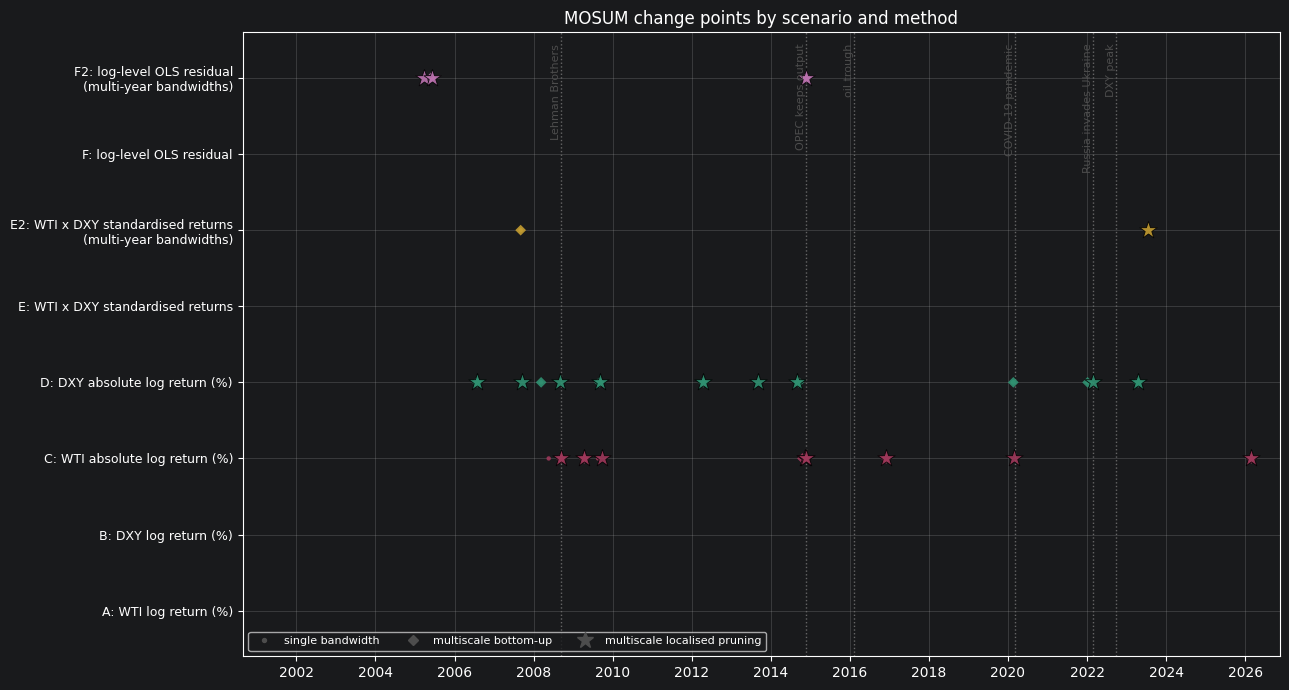

In [18]:
EVENTS = {
    "2008-09-15": "Lehman Brothers",
    "2014-11-27": "OPEC keeps output",
    "2016-02-11": "oil trough",
    "2020-03-11": "COVID-19 pandemic",
    "2022-02-24": "Russia invades Ukraine",
    "2022-09-28": "DXY peak",
}
STYLE = {"single bandwidth": (".", 40), BOTTOM_UP: ("D", 30), HEADLINE: ("*", 170)}
style_of = lambda m: "single bandwidth" if m.startswith("single") else m

valid = all_cpts[all_cpts["valid_assumptions"]].copy()
valid["style"] = valid["method"].map(style_of)
names = [results[k]["name"] for k in VALID_KEYS]

fig, ax = plt.subplots(figsize=(13, 7))
for j, name in enumerate(names):
    sub = valid[valid["scenario"] == name]
    for style, (mk, size) in STYLE.items():
        pts = sub[sub["style"] == style]
        ax.scatter(pts["date"], np.full(len(pts), j), marker=mk, s=size, color=f"C{j}",
                   edgecolor="black" if style == HEADLINE else "none", linewidths=0.6, alpha=0.9, zorder=3)
for d, label in EVENTS.items():
    ax.axvline(pd.Timestamp(d), color="0.4", ls=":", lw=1)
    ax.text(pd.Timestamp(d), len(names) - 0.55, label, rotation=90, fontsize=8, va="top", ha="right", color="0.3")
ax.set_yticks(range(len(names)))
ax.set_yticklabels([n.replace(", multi-year bandwidths", "\n(multi-year bandwidths)") for n in names], fontsize=9)
ax.set_ylim(-0.6, len(names) - 0.4)
ax.set_xlim(prices.index.min(), prices.index.max())
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("MOSUM change points by scenario and method")
ax.legend([Line2D([], [], marker=mk, ls="none", color="0.3", ms=np.sqrt(size) * 0.9) for mk, size in STYLE.values()],
          list(STYLE), loc="lower left", fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

### 6.3 Breaks shared by WTI and DXY
Headline change points of the WTI scenario and the DXY scenario that fall within `MATCH_TOL_DAYS` calendar days of each other. A shared drift or volatility break is suggestive of a common shock. The correlation scenarios (E, E2) and the level-relationship scenarios (F, F2) are listed separately because they are joint by construction.

In [19]:
def headline_dates(key):
    t = results[key]["table"]
    return sorted(pd.to_datetime(t.loc[t["method"] == HEADLINE, "date"]))


def match_breaks(d1, d2, tol_days=MATCH_TOL_DAYS):
    rows = [{"date_WTI": a.date(), "date_DXY": b.date(), "gap_days": (b - a).days}
            for a in d1 for b in d2 if abs((b - a).days) <= tol_days]
    return pd.DataFrame(rows, columns=["date_WTI", "date_DXY", "gap_days"])


for k1, k2, label in [("A", "B", "drift (A vs B)"), ("C", "D", "volatility (C vs D)")]:
    matched = match_breaks(headline_dates(k1), headline_dates(k2))
    print(f"Shared {label} breaks within +/- {MATCH_TOL_DAYS} calendar days: {len(matched)} "
          f"(WTI has {len(headline_dates(k1))}, DXY has {len(headline_dates(k2))})")
    display(matched)

for key in ["E", "E2", "F", "F2"]:
    print(f"{results[key]['name']}: headline breaks:",
          ", ".join(d.strftime("%Y-%m-%d") for d in headline_dates(key)) or "none")

Shared drift (A vs B) breaks within +/- 60 calendar days: 0 (WTI has 0, DXY has 0)


,date_WTI,date_DXY,gap_days


Shared volatility (C vs D) breaks within +/- 60 calendar days: 2 (WTI has 8, DXY has 9)


,date_WTI,date_DXY,gap_days
0,2008-09-12,2008-08-28,-15
1,2009-09-24,2009-09-02,-22


E: WTI x DXY standardised returns: headline breaks: none
E2: WTI x DXY standardised returns, multi-year bandwidths: headline breaks: 2023-07-14
F: log-level OLS residual: headline breaks: none
F2: log-level OLS residual, multi-year bandwidths: headline breaks: 2005-03-23, 2005-06-10, 2014-11-26


### 6.4 Sensitivity to the significance level
Number of headline (localised-pruning) change points at $\alpha$ = 1%, 5% and 10%, keeping each scenario's bandwidth set and autocorrelation adjustment. A break that survives at 1% is a robust one; counts that balloon at 10% indicate a scenario where the procedure is close to its detection boundary.

In [20]:
sens = {}
for key in VALID_KEYS:
    r = results[key]
    for a in (0.01, 0.05, 0.10):
        sens[(r["name"], a)] = len(run_multiscale(r["series"], "local_prune", alpha=a, ratio=r["ratio"], Gs=r["Gs"]).cpts)
sens = pd.Series(sens).unstack()
sens.columns = [f"alpha={a:.2f}" for a in sens.columns]
display(sens.reindex([results[k]["name"] for k in VALID_KEYS]))

,alpha=0.01,alpha=0.05,alpha=0.10
A: WTI log return (%),0,0,0
B: DXY log return (%),0,0,0
C: WTI absolute log return (%),4,8,9
D: DXY absolute log return (%),1,9,9
E: WTI x DXY standardised returns,0,0,0
"E2: WTI x DXY standardised returns, multi-year bandwidths",0,1,2
F: log-level OLS residual,0,0,0
"F2: log-level OLS residual, multi-year bandwidths",1,3,5


### 6.5 Sensitivity to the bandwidth set
The multiscale procedures depend on the bandwidths offered to them. Each base scenario (A–F) is re-run under localised pruning with the package's own `bandwidths_default` grid, the quarter/half-year/year set, the multi-year set and a wide set spanning both (scenario-specific autocorrelation adjustment kept).

In [21]:
n_default = mosum.bandwidths_default(len(results["A"]["series"]))
grids = {"package default " + str([int(g) for g in n_default]): [int(g) for g in n_default],
         "quarter/half/year " + str(BANDWIDTHS): BANDWIDTHS,
         "multi-year " + str(SLOW_BANDWIDTHS): SLOW_BANDWIDTHS,
         "wide " + str(sorted(set(BANDWIDTHS) | set(SLOW_BANDWIDTHS))): sorted(set(BANDWIDTHS) | set(SLOW_BANDWIDTHS))}
rows = {}
for key in ["A", "B", "C", "D", "E", "F"]:
    r = results[key]
    rows[r["name"]] = {g: len(run_multiscale(r["series"], "local_prune", ratio=r["ratio"], Gs=G).cpts)
                       for g, G in grids.items()}
display(pd.DataFrame(rows).T)

,"package default [10, 20, 30, 50, 80, 130, 210, 340]","quarter/half/year [63, 126, 252]","multi-year [252, 504, 756]","wide [63, 126, 252, 504, 756]"
A: WTI log return (%),0,0,0,0
B: DXY log return (%),0,0,0,0
C: WTI absolute log return (%),7,8,8,8
D: DXY absolute log return (%),10,9,12,11
E: WTI x DXY standardised returns,0,0,1,1
F: log-level OLS residual,0,0,3,3


## 7. Results of the 2026-11-19 run and how to read them

The commentary below describes the output of the run saved in this notebook (data through 2026-11-19). Re-running on a later date will shift the last regime and may add or remove the most recent change point, which is the one with the widest confidence interval.

* **Drift (A, B): no change points** at any bandwidth, any method, any $\alpha$. Neither the oil nor the dollar daily return has a detectable shift in its mean. This is the expected answer for liquid daily returns and is a useful sanity check of the method: MOSUM is not inventing breaks where the series is close to white noise.
* **Oil volatility (C): eight regimes.** Breaks at 2008-09-12 and 2009-04-13 bracket the financial crisis (mean absolute return 4.7% a day versus 1.7% before), 2014-11-12/25 marks the start of the 2014–16 collapse regime, 2016-12-02 its end, 2020-02-26 the COVID shock, and 2026-02-26 the start of the current high-volatility regime. The two November-2014 dates nine days apart are one break that localised pruning kept from two scales; bottom-up merging reports a single 2014-10-21 break instead. At $\alpha$ = 1% four breaks survive.
* **Dollar volatility (D): nine regimes** with smaller jumps: 2006-07-28, 2007-09-17, 2008-08-28 and 2009-09-02 around the crisis, 2012-04-16, 2013-09-03 and 2014-08-28 across the taper period, 2022-02-22 (Ukraine invasion and the 2022 dollar rally) and 2023-04-18. Only one survives at $\alpha$ = 1% and the confidence intervals are wide (up to about 400 trading days), so these are softer regimes than the oil ones.
* **Shared volatility breaks (6.3):** two of them, both in the 2008–09 crisis (WTI 2008-09-12 vs DXY 2008-08-28; WTI 2009-09-24 vs DXY 2009-09-02). Every other volatility break is specific to one market. The 2014 oil collapse, the 2020 pandemic and 2022 do not produce matched breaks within 60 days.
* **Correlation (E, E2):** at quarterly-to-annual bandwidths the detector maxima sit just under their thresholds, so no break is declared. At multi-year bandwidths (E2) only the three-year window crosses its threshold, and the two multiscale procedures keep different single breaks: bottom-up merging keeps **2007-09-04**, the onset of the strongly negative oil–dollar correlation regime (rolling correlation around −0.4 to −0.5 through 2013), while localised pruning keeps **2023-07-14**, after which the regime correlation flips from about −0.19 to about +0.15. Both features are plain in the rolling-correlation overlay; the Schwarz criterion simply cannot afford both at once. The 2023 break has a wide interval (mid-2022 to mid-2024), disappears at $\alpha$ = 1% and is joined by a second break at 10%. These are the dates most relevant to the de-dollarisation question, and they are only visible once the bandwidth matches the multi-year horizon over which the relationship evolves.
* **Level relationship (F, F2):** at standard bandwidths the adjusted thresholds (inflated by about 14 after the long-run-variance correction) are never crossed. At the three-year bandwidth (F2) the detector exceeds the adjusted threshold at two points: **spring 2005** (localised pruning splits it into 2005-03-23 and 2005-06-10, bottom-up reports 2005-05-27), when the oil level shifted up by about 0.5 log points relative to what the dollar explains, and **2014-11-26**, the OPEC no-cut meeting, after which the residual's mean rises slightly and its standard deviation nearly doubles, i.e. the level relationship became looser rather than shifting cleanly. One break survives at $\alpha$ = 1% and five appear at 10%. The residual's ADF $p$-value is close to 5%, so treat F2 dates as descriptive.
* **Bandwidth sensitivity (6.5):** the oil-volatility count is stable (seven or eight breaks) across every grid, the dollar-volatility count moves between nine and twelve, and the two joint scenarios only register once a multi-year bandwidth is in the grid. Choosing the bandwidth is choosing the horizon of the regimes one is asking about.
* **Reference (G, H):** dozens of "breaks" on the raw log levels, as expected from applying a mean-change detector to integrated data. Never report these.
* **Caveats.** Asymptotic critical values assume uncorrelated noise; the Newey–West inflation is a pragmatic correction, not an exact one. Bootstrap intervals are iid and therefore optimistic in C–F2. Front-month futures contain roll effects; constant-maturity or spot series are a useful robustness check. All dates are first trading days of the new regime and carry the uncertainty shown in the confidence-interval table.

Outputs written to the `ai_folder` directory: `wti_dxy_prices.csv`, `mosum_change_points.csv`, `mosum_headline_confidence_intervals.csv`.